# Shannon–Fano y Huffman: evaluar códigos dados y cambios en la fuente

**Tema 2 · Apartados 2.3–2.4 · Demostración orientativa: 10–20 minutos.**

Resolver un problema de eficiencia, desajuste del modelo y coste de enviar el libro de códigos.

## Cómo experimentar

Ejecuta todo de arriba abajo. Cambia un parámetro, predice qué ocurrirá y vuelve a ejecutar todas las celdas.
En Colab: *Entorno de ejecución → Ejecutar todas*. En Jupyter: *Kernel → Restart Kernel and Run All Cells*.
Los comentarios `#@param` permiten formularios en Colab; en Jupyter puedes editar los valores.

En la web, «Abrir en Colab» abre este cuaderno directamente en el navegador.
«Descargar cuaderno .ipynb» permite guardarlo y abrirlo en Jupyter o importarlo en Colab.
Puedes guardar una copia en tu Google Drive o descargar tu cuaderno desde Colab para conservar cambios.
Los cambios en tu sesión no modifican los originales de este repositorio.
La vista HTML muestra los resultados guardados; no recalcula las gráficas.
Los datos se generan en el propio cuaderno. No se instalan paquetes ni se descargan datos.
Solo se necesitan NumPy, Matplotlib y la biblioteca estándar de Python; IPython muestra las tablas.

## Modelo y pregunta

Una fuente tiene cinco símbolos. Para la distribución de diseño
$q=(0.40,0.15,0.15,0.15,0.15)$ se han obtenido estos **códigos dados**:

| Símbolo | q de diseño | Huffman | Shannon–Fano | Longitud fija |
|---|---:|---|---|---|
| a1 | 0.40 | 0 | 00 | 000 |
| a2 | 0.15 | 100 | 01 | 001 |
| a3 | 0.15 | 101 | 10 | 010 |
| a4 | 0.15 | 110 | 110 | 011 |
| a5 | 0.15 | 111 | 111 | 100 |

Estudiamos $L=\sum_i p_i l_i$, la redundancia $L-H(X)$ y la eficiencia $H(X)/L$.
No se construyen códigos nuevos: las palabras de la tabla permanecen fijas durante el experimento.
Si la distribución real $p$ cambia, el código diseñado mediante Huffman para $q$ puede dejar de ser
compacto para $p$. Su nombre identifica su origen, no garantiza que siga siendo óptimo.

Variamos la frecuencia del primer símbolo y repartimos el resto por igual:
$$p=(p_1,(1-p_1)/4,(1-p_1)/4,(1-p_1)/4,(1-p_1)/4).$$
Esta familia permite resolver analíticamente cuándo conviene cada código dado.

In [1]:
import math
import html
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False})
AZUL = '#006d75'
NARANJA = '#b95028'
GRIS = '#617583'

def tabla(cabeceras, filas):
    def celda(x):
        return html.escape(str(x))
    cuerpo = ''.join('<tr>' + ''.join('<td>' + celda(x) + '</td>' for x in fila)
                     + '</tr>' for fila in filas)
    display(HTML('<div style="overflow-x:auto"><table><thead><tr>'
                 + ''.join('<th>' + celda(x) + '</th>' for x in cabeceras)
                 + '</tr></thead><tbody>' + cuerpo + '</tbody></table></div>'))

def entropia(prob):
    p = np.asarray(prob, dtype=float)
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))

## Parámetros

Cambia un valor cada vez. Los rangos y las unidades aparecen en los comentarios.

In [2]:
#@title Parámetros
prob_primer_simbolo = 0.4 #@param {type:"slider", min:0.05, max:0.95, step:0.05}
n_simbolos = 1000 #@param {type:"integer"}
cabecera_bits = 64 #@param {type:"slider", min:0, max:512, step:16}
assert .05 <= prob_primer_simbolo <= .95
assert isinstance(n_simbolos, int) and 1 <= n_simbolos <= 100000
assert isinstance(cabecera_bits, int) and 0 <= cabecera_bits <= 512
simbolos = ['a1', 'a2', 'a3', 'a4', 'a5']
q = np.array([.4, .15, .15, .15, .15])
p = np.array([prob_primer_simbolo]+[(1-prob_primer_simbolo)/4]*4)
codigos = {
    'Huffman para q': ['0', '100', '101', '110', '111'],
    'Shannon–Fano para q': ['00', '01', '10', '110', '111'],
    'Longitud fija': ['000', '001', '010', '011', '100'],
}
longitudes = {nombre: np.array([len(c) for c in palabras]) for nombre, palabras in codigos.items()}
H = entropia(p)
medias = {nombre: float(p @ ls) for nombre, ls in longitudes.items()}

## 1. Longitud media y eficiencia con las probabilidades actuales

El panel izquierdo compara la frecuencia real con la distribución para la que se diseñaron los códigos.
El derecho compara la longitud media con la entropía. Las longitudes enteras de las palabras no cambian,
pero sí cambia el peso de cada palabra en el promedio.

Símbolo,q de diseño,p actual,Huffman dado,Shannon–Fano dado,Fijo
a1,0.400,0.400,0,00,000
a2,0.150,0.150,100,01,001
a3,0.150,0.150,101,10,010
a4,0.150,0.150,110,110,011
a5,0.150,0.150,111,111,100


Código dado,L (bits/símbolo),L − H,Eficiencia
Huffman para q,2.2000,0.0290,98.68 %
Shannon–Fano para q,2.3000,0.1290,94.39 %
Longitud fija,3.0000,0.8290,72.37 %


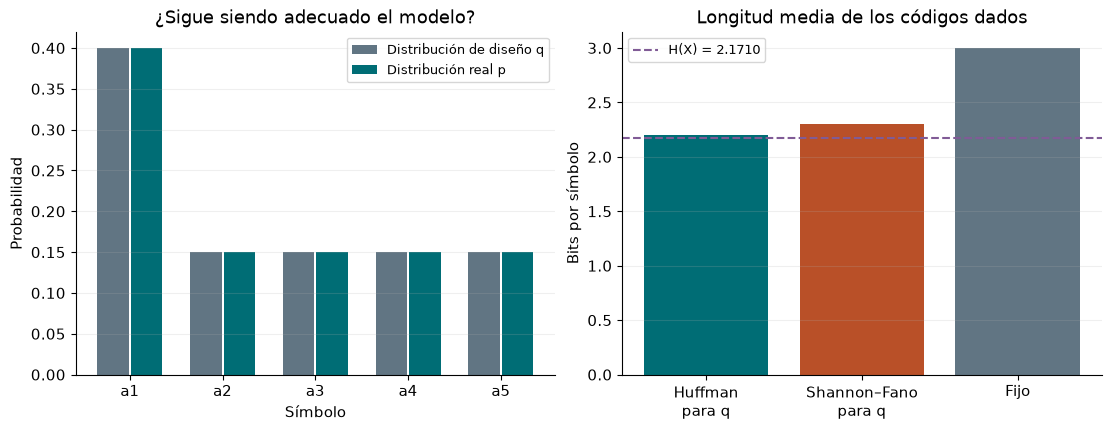

In [3]:
tabla(['Símbolo', 'q de diseño', 'p actual', 'Huffman dado', 'Shannon–Fano dado', 'Fijo'],
      [(s, f'{qi:.3f}', f'{pi:.3f}', codigos['Huffman para q'][i],
        codigos['Shannon–Fano para q'][i], codigos['Longitud fija'][i])
       for i, (s, qi, pi) in enumerate(zip(simbolos, q, p))])
tabla(['Código dado', 'L (bits/símbolo)', 'L − H', 'Eficiencia'],
      [(nombre, f'{L:.4f}', f'{L-H:.4f}', f'{100*H/L:.2f} %') for nombre, L in medias.items()])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout='constrained')
xs = np.arange(5)
axes[0].bar(xs-.18, q, width=.34, color=GRIS, label='Distribución de diseño q')
axes[0].bar(xs+.18, p, width=.34, color=AZUL, label='Distribución real p')
axes[0].set_xticks(xs, simbolos)
axes[0].set(xlabel='Símbolo', ylabel='Probabilidad', title='¿Sigue siendo adecuado el modelo?')
axes[0].legend(fontsize=9)
etiquetas = ['Huffman\npara q', 'Shannon–Fano\npara q', 'Fijo']
axes[1].bar(range(3), list(medias.values()), color=[AZUL, NARANJA, GRIS])
axes[1].set_xticks(range(3), etiquetas)
axes[1].axhline(H, color='#805b96', ls='--', label=f'H(X) = {H:.4f}')
axes[1].set(ylabel='Bits por símbolo', title='Longitud media de los códigos dados')
axes[1].legend(fontsize=9)
for ax in axes: ax.grid(axis='y', alpha=.2)
plt.show()

## 2. ¿Cuándo cambia el código que conviene usar?

Para esta familia de fuentes, basta sustituir en la suma ponderada:
$$L_{\mathrm H}=p_1+3(1-p_1)=3-2p_1,$$
$$L_{\mathrm{SF}}=2p_1+\frac{2+2+3+3}{4}(1-p_1)=2.5-0.5p_1.$$
Se igualan en $p_1=1/3$. Estas curvas evalúan **las dos asignaciones de la tabla**;
no son las prestaciones de algoritmos que vuelvan a calcular el código para cada punto.

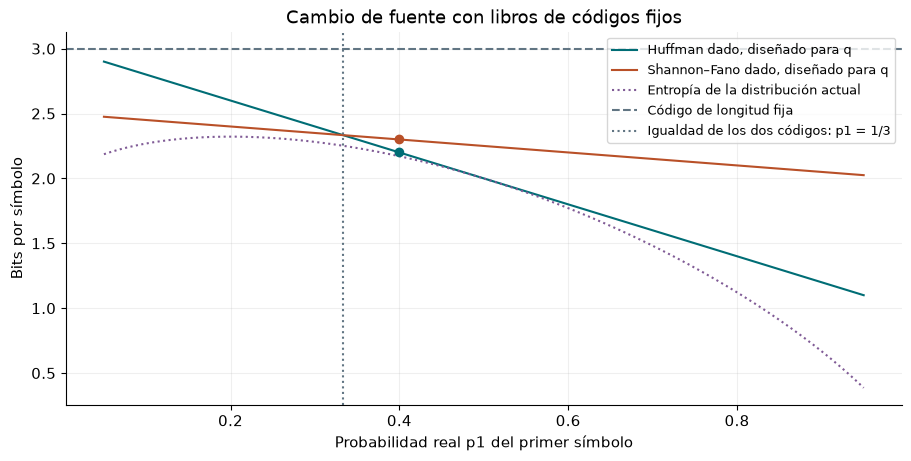

In [4]:
ps = np.linspace(.05, .95, 401)
LH = 3-2*ps
LSF = 2.5-.5*ps
Hs = np.array([entropia([x]+[(1-x)/4]*4) for x in ps])
fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
ax.plot(ps, LH, color=AZUL, label='Huffman dado, diseñado para q')
ax.plot(ps, LSF, color=NARANJA, label='Shannon–Fano dado, diseñado para q')
ax.plot(ps, Hs, ':', color='#805b96', label='Entropía de la distribución actual')
ax.axhline(3, ls='--', color=GRIS, label='Código de longitud fija')
ax.axvline(1/3, ls=':', color=GRIS, label='Igualdad de los dos códigos: p1 = 1/3')
ax.scatter([prob_primer_simbolo]*2, [medias['Huffman para q'], medias['Shannon–Fano para q']],
           c=[AZUL, NARANJA], zorder=4)
ax.set(xlabel='Probabilidad real p1 del primer símbolo', ylabel='Bits por símbolo',
       title='Cambio de fuente con libros de códigos fijos')
ax.legend(fontsize=9); ax.grid(alpha=.2); plt.show()

## 3. Un paquete corto también paga la cabecera

Supongamos que para usar uno de los códigos variables hay que enviar $B$ bits adicionales
de modelo o libro de códigos **en cada paquete**. La longitud fija no necesita ese modelo adicional.
El alfabeto, el número de símbolos y el encuadre común ya los conoce el receptor.
El valor $B$ es una hipótesis de presupuesto configurable, no una serialización del diccionario.

La longitud esperada total es $nL+B$. Frente a $3n$ bits, hay ahorro cuando
$$n>\frac{B}{3-L}.$$
Si el modelo se comparte entre muchos paquetes, se puede repartir su coste o poner $B=0$.

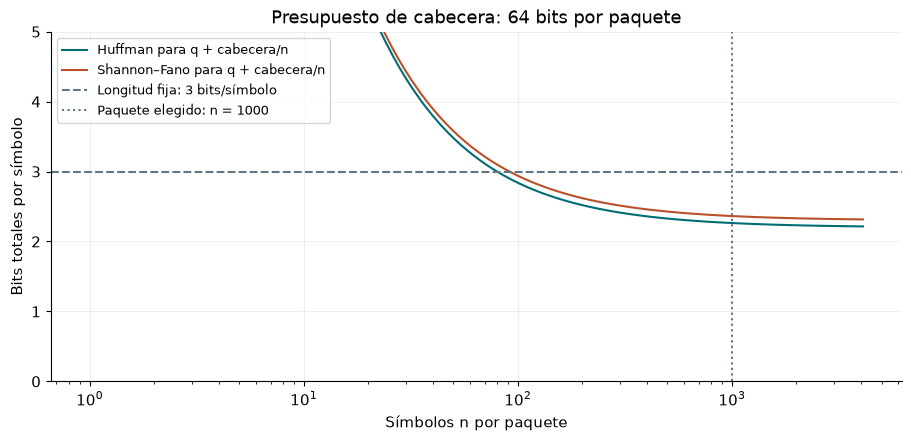

El eje vertical se limita a 5 bits/símbolo; los paquetes más cortos pueden superar ese valor.


Código,Bits esperados totales,Ahorro frente a 3n,Primer n con ahorro estricto
Huffman para q,2264.00,24.53 %,81
Shannon–Fano para q,2364.00,21.20 %,92


In [5]:
ns = np.unique(np.geomspace(1, max(4096, n_simbolos), 120).astype(int))
fig, ax = plt.subplots(figsize=(9, 4.3), layout='constrained')
resultados = []
for nombre, color in [('Huffman para q', AZUL), ('Shannon–Fano para q', NARANJA)]:
    L = medias[nombre]
    ax.plot(ns, L+cabecera_bits/ns, color=color, label=nombre+' + cabecera/n')
    total = n_simbolos*L+cabecera_bits
    minimo_n = math.floor(cabecera_bits/(3-L)+1e-10)+1
    resultados.append((nombre, f'{total:.2f}', f'{100*(1-total/(3*n_simbolos)):.2f} %', minimo_n))
ax.axhline(3, color=GRIS, ls='--', label='Longitud fija: 3 bits/símbolo')
ax.axvline(n_simbolos, color=GRIS, ls=':', label=f'Paquete elegido: n = {n_simbolos}')
ax.set(xscale='log', ylim=(0, 5), xlabel='Símbolos n por paquete', ylabel='Bits totales por símbolo',
       title=f'Presupuesto de cabecera: {cabecera_bits} bits por paquete')
ax.legend(fontsize=9); ax.grid(alpha=.2); plt.show()
print('El eje vertical se limita a 5 bits/símbolo; los paquetes más cortos pueden superar ese valor.')
tabla(['Código', 'Bits esperados totales', 'Ahorro frente a 3n', 'Primer n con ahorro estricto'], resultados)

## Antes de mirar la explicación

1. Con p1=0.4, ¿qué código tiene menor longitud media y qué eficiencia alcanza?
2. Cambia p1 a 0.1. ¿Que gane el código dado de Shannon–Fano contradice la optimalidad de Huffman?
3. ¿Por qué el cambio de preferencia se produce en p1=1/3?
4. Con p1=0.4 y una cabecera de 64 bits, ¿cuántos símbolos hacen falta para ahorrar bits?
5. ¿Puede un código con alta eficiencia aumentar el tamaño de un paquete corto?

## Explicación de lo observado

1. $H\simeq2.171$, $L_{\mathrm H}=2.2$ y $L_{\mathrm{SF}}=2.3$.
   Las eficiencias son aproximadamente 98.68 % y 94.39 %.
2. No. Se sigue usando el Huffman construido para **otra distribución**. Con p1=0.1,
   sus longitudes medias son 2.8 y 2.45, respectivamente. Reconstruir Huffman para la nueva fuente
   volvería a dar un código compacto, pero esa construcción no forma parte del cuaderno.
3. Al igualar $3-2p_1$ con $2.5-0.5p_1$ se obtiene $p_1=1/3$.
   Debajo de ese valor favorece a Shannon–Fano dado; encima, a Huffman dado.
4. Para Huffman, $64/(3-2.2)=80$: la igualdad está en 80 y el ahorro estricto empieza en 81.
   Para Shannon–Fano, $64/0.7\simeq91.43$: se necesitan al menos 92.
5. Sí. La eficiencia $H/L$ mide las palabras del código. La cabecera puede superar el ahorro
   de esas palabras si hay pocos símbolos para amortizarla.

## Comprobación del modelo

Comprobamos las fórmulas del presupuesto y los resultados de referencia.

In [6]:
assert np.isclose(medias['Huffman para q'], 3-2*prob_primer_simbolo)
assert np.isclose(medias['Shannon–Fano para q'], 2.5-.5*prob_primer_simbolo)
assert all(L >= H-1e-12 for L in medias.values())
assert np.isclose(q @ longitudes['Huffman para q'], 2.2)
assert np.isclose(q @ longitudes['Shannon–Fano para q'], 2.3)
assert np.isclose(3-2/3, 2.5-.5/3)
assert 80*2.2+64 == 80*3 and 81*2.2+64 < 81*3
print('Longitudes ponderadas, punto de igualdad y amortización comprobados.')

Longitudes ponderadas, punto de igualdad y amortización comprobados.


## Referencias

Ejemplo y código propios para TDI.

- TDI, tema 2, apartados 2.3–2.4: «Longitud media y eficiencia» y «Shannon–Fano y Huffman».

Los supuestos y las convenciones de este experimento se explican en «Modelo y pregunta».